<a href="https://colab.research.google.com/github/eccidev/databases.github.io/blob/main/Principios_Matematicos_IA_2_Sesiones_Leidy_Vargas.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Principios Matemáticos de la Inteligencia Artificial
## Laboratorio en Google Colab — 2 sesiones

**Objetivo general:** comprender, mediante ejemplos numéricos y visuales, cómo las matemáticas fundamentales aparecen dentro de los algoritmos de inteligencia artificial.

### Estructura
- **Sesión 1:** Álgebra lineal, funciones, cálculo y probabilidad.
- **Sesión 2:** Funciones de costo, optimización, descenso de gradiente y redes neuronales.

### Metodología
Cada tema sigue la secuencia:

**concepto matemático → ejemplo numérico → visualización → relación con IA → ejercicio**

In [5]:
# Librerías utilizadas
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import make_classification
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import mean_squared_error, accuracy_score
from sklearn.model_selection import train_test_split

np.set_printoptions(precision=4, suppress=True)
print("Entorno listo.")

Entorno listo.


# SESIÓN 1 — Matemáticas que representan datos y aprendizaje

## Resultados de aprendizaje
Al finalizar esta sesión el estudiante podrá:

1. Interpretar vectores y matrices como representaciones de datos.
2. Entender el producto punto como una medida de combinación/similitud.
3. Relacionar funciones lineales con modelos predictivos.
4. Interpretar la derivada como tasa de cambio.
5. Comprender la probabilidad como herramienta para modelar incertidumbre.

## 1. Escalares, vectores y matrices

Un **escalar** es un solo número:

$$
x = 5
$$

Un **vector** es una colección ordenada de números:

$$
\mathbf{x} =
\begin{bmatrix}
x_1\\
x_2\\
x_3
\end{bmatrix}
$$

En IA, un vector puede representar las características de una observación.

Ejemplo: una vivienda puede representarse mediante:

$$
\mathbf{x} =
[\text{área},\text{habitaciones},\text{edad}]
$$

Una **matriz** permite almacenar muchas observaciones:

$$
X=
\begin{bmatrix}
x_{11}&x_{12}&x_{13}\\
x_{21}&x_{22}&x_{23}\\
\vdots&\vdots&\vdots
\end{bmatrix}
$$

Las filas suelen representar observaciones y las columnas características.

In [ ]:
# Ejemplo: tres viviendas representadas matemáticamente
X = np.array([
    [60,  2, 15],
    [85,  3,  8],
    [120, 4,  3]
])

columnas = ["Área (m²)", "Habitaciones", "Edad (años)"]
df = pd.DataFrame(X, columns=columnas)
df

,Área (m²),Habitaciones,Edad (años)
0,60,2,15
1,85,3,8
2,120,4,3


### ¿Dónde aparece esto en IA?

Prácticamente todos los algoritmos reciben los datos como una matriz \(X\).

Por ejemplo, si tenemos 1.000 pacientes y medimos 20 variables, el conjunto de datos puede representarse como:

$$
X \in \mathbb{R}^{1000\times20}
$$

La IA comienza convirtiendo objetos del mundo real en números.

## 2. Producto punto: el corazón de muchos modelos

Dados dos vectores:

$$
\mathbf{x}=[x_1,x_2,\ldots,x_n]
$$

$$
\mathbf{w}=[w_1,w_2,\ldots,w_n]
$$

su producto punto es:

$$
\mathbf{x}\cdot\mathbf{w}
=
\sum_{i=1}^{n}x_iw_i
$$

En aprendizaje automático, \(\mathbf{w}\) suele contener los **pesos del modelo**.

Un modelo lineal básico calcula:

$$
\hat{y}=\mathbf{x}\cdot\mathbf{w}+b
$$

donde \(b\) es el sesgo.

In [ ]:
# Ejemplo manual de una neurona/modelo lineal
x = np.array([2.0, 3.0])
w = np.array([0.5, 1.2])
b = -0.4

producto_punto = np.dot(x, w)
salida = producto_punto + b

print("x =", x)
print("w =", w)
print("x · w =", producto_punto)
print("Salida = x · w + b =", salida)

x = [2. 3.]
w = [0.5 1.2]
x · w = 4.6
Salida = x · w + b = 4.199999999999999


### Interpretación

$$
[2,3]\cdot[0.5,1.2]
=
2(0.5)+3(1.2)=4.6
$$

Al sumar el sesgo:

$$
\hat y=4.6-0.4=4.2
$$

Esta operación es una versión extremadamente simple de lo que ocurre dentro de una neurona artificial.

## 3. Geometría de vectores y similitud

La norma euclidiana de un vector es:

$$
||\mathbf{x}||_2=\sqrt{x_1^2+x_2^2+\cdots+x_n^2}
$$

La similitud coseno es:

$$
\cos(\theta)=
\frac{\mathbf{x}\cdot\mathbf{y}}
{||\mathbf{x}||\,||\mathbf{y}||}
$$

En IA se utiliza para comparar embeddings de textos, imágenes y documentos.

Similitud coseno a-b: 0.9999999999999998
Similitud coseno a-c: 0.0


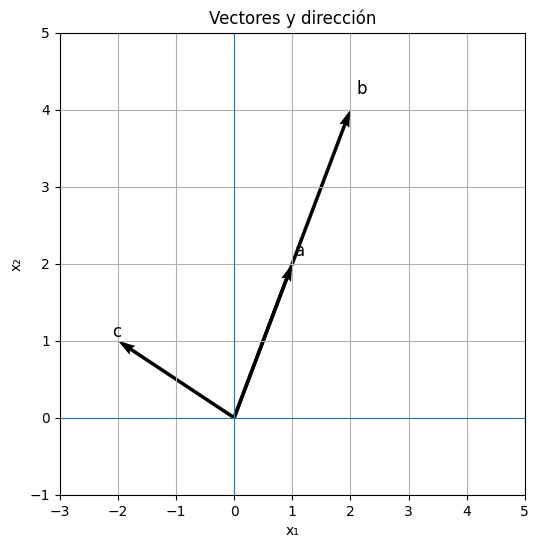

In [ ]:
a = np.array([1., 2.])
b = np.array([2., 4.])
c = np.array([-2., 1.])

def cosine_similarity_manual(x, y):
    return np.dot(x, y) / (np.linalg.norm(x) * np.linalg.norm(y))

print("Similitud coseno a-b:", cosine_similarity_manual(a, b))
print("Similitud coseno a-c:", cosine_similarity_manual(a, c))

plt.figure(figsize=(6,6))
origen = np.zeros(2)
for v, nombre in [(a,"a"), (b,"b"), (c,"c")]:
    plt.quiver(*origen, *v, angles='xy', scale_units='xy', scale=1)
    plt.text(v[0]*1.05, v[1]*1.05, nombre, fontsize=12)

plt.xlim(-3,5)
plt.ylim(-1,5)
plt.axhline(0, linewidth=0.8)
plt.axvline(0, linewidth=0.8)
plt.grid(True)
plt.title("Vectores y dirección")
plt.xlabel("x₁")
plt.ylabel("x₂")
plt.show()

## 4. Funciones: convertir entradas en salidas

Un modelo de IA puede verse como una función:

$$
f:X\rightarrow Y
$$

Para una regresión lineal:

$$
f(x)=wx+b
$$

El parámetro \(w\) controla la pendiente y \(b\) el desplazamiento.

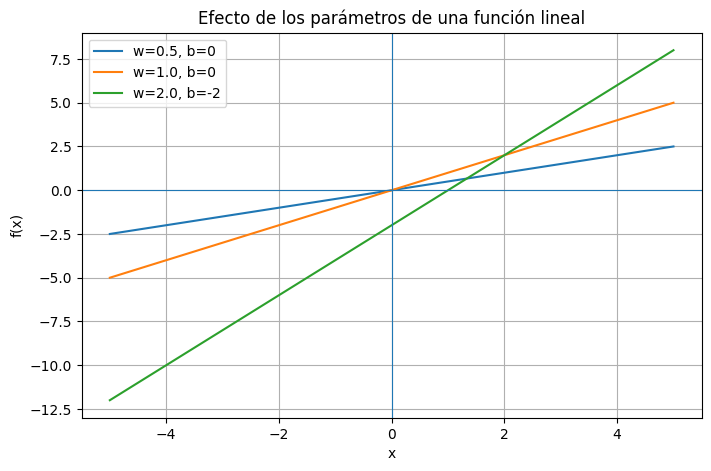

In [ ]:
x = np.linspace(-5, 5, 200)

parametros = [
    (0.5, 0),
    (1.0, 0),
    (2.0, -2)
]

plt.figure(figsize=(8,5))
for w, b in parametros:
    y = w*x + b
    plt.plot(x, y, label=f"w={w}, b={b}")

plt.axhline(0, linewidth=0.8)
plt.axvline(0, linewidth=0.8)
plt.grid(True)
plt.legend()
plt.title("Efecto de los parámetros de una función lineal")
plt.xlabel("x")
plt.ylabel("f(x)")
plt.show()

## 5. Derivada: cómo cambia una función

La derivada de \(f(x)\) indica cómo cambia la salida ante pequeños cambios en la entrada:

$$
f'(x)=\lim_{h\rightarrow0}\frac{f(x+h)-f(x)}{h}
$$

Ejemplo:

$$
f(x)=x^2
$$

$$
f'(x)=2x
$$

En IA, las derivadas permiten responder:

> ¿En qué dirección debemos modificar los parámetros para reducir el error?

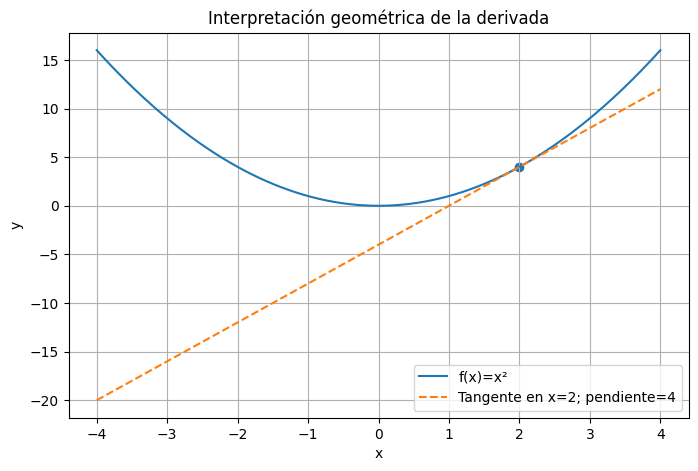

In [ ]:
def f(x):
    return x**2

def df(x):
    return 2*x

x = np.linspace(-4,4,300)
y = f(x)

x0 = 2
pendiente = df(x0)
tangente = f(x0) + pendiente*(x-x0)

plt.figure(figsize=(8,5))
plt.plot(x, y, label="f(x)=x²")
plt.plot(x, tangente, "--", label=f"Tangente en x={x0}; pendiente={pendiente}")
plt.scatter([x0], [f(x0)])
plt.grid(True)
plt.legend()
plt.title("Interpretación geométrica de la derivada")
plt.xlabel("x")
plt.ylabel("y")
plt.show()

## 6. Derivada numérica

Una computadora puede aproximar una derivada mediante:

$$
f'(x)\approx\frac{f(x+h)-f(x-h)}{2h}
$$

Este principio ayuda a comprender cómo un sistema computacional puede estimar cambios.

In [ ]:
def derivada_numerica(funcion, x, h=1e-5):
    return (funcion(x+h) - funcion(x-h))/(2*h)

for punto in [-2, -1, 0, 1, 2]:
    exacta = df(punto)
    aproximada = derivada_numerica(f, punto)
    print(f"x={punto:>2} | exacta={exacta:>6.2f} | numérica={aproximada:>8.5f}")

x=-2 | exacta= -4.00 | numérica=-4.00000
x=-1 | exacta= -2.00 | numérica=-2.00000
x= 0 | exacta=  0.00 | numérica= 0.00000
x= 1 | exacta=  2.00 | numérica= 2.00000
x= 2 | exacta=  4.00 | numérica= 4.00000


## 7. Probabilidad e incertidumbre

Muchos sistemas de IA no producen una certeza absoluta, sino una probabilidad.

Si \(Y\) representa una clase:

$$
P(Y=1|X)
$$

puede interpretarse como la probabilidad de que una observación pertenezca a la clase 1 dadas sus características.

Una distribución Bernoulli modela eventos binarios:

$$
P(X=x)=p^x(1-p)^{1-x}
$$

donde:

- \(p\): probabilidad de éxito.
- \(1-p\): probabilidad de fracaso.

Probabilidad teórica: 0.7
Frecuencia observada: 0.712


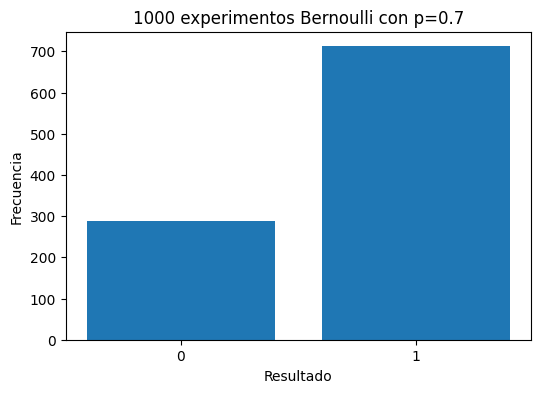

In [ ]:
np.random.seed(42)

p = 0.7
resultados = np.random.binomial(1, p, size=1000)

print("Probabilidad teórica:", p)
print("Frecuencia observada:", resultados.mean())

conteo = pd.Series(resultados).value_counts().sort_index()

plt.figure(figsize=(6,4))
plt.bar(["0", "1"], [conteo.get(0,0), conteo.get(1,0)])
plt.title("1000 experimentos Bernoulli con p=0.7")
plt.xlabel("Resultado")
plt.ylabel("Frecuencia")
plt.show()

## 8. Esperanza y varianza

Para una variable aleatoria \(X\):

$$
E[X]=\sum_x xP(X=x)
$$

La varianza mide dispersión:

$$
Var(X)=E[(X-\mu)^2]
$$

En aprendizaje automático estas ideas aparecen en:

- estimación estadística,
- inicialización de parámetros,
- análisis de ruido,
- incertidumbre,
- validación de modelos.

In [ ]:
datos = np.array([2, 4, 4, 4, 5, 5, 7, 9])

media = np.mean(datos)
varianza = np.var(datos)

print("Datos:", datos)
print("Media:", media)
print("Varianza:", varianza)
print("Desviación estándar:", np.std(datos))

Datos: [2 4 4 4 5 5 7 9]
Media: 5.0
Varianza: 4.0
Desviación estándar: 2.0


# Actividad de cierre — Sesión 1

### Ejercicio 1
Calcule manualmente:

$$
[2,1,3]\cdot[0.5,-1,2]
$$

### Ejercicio 2
Para:

$$
f(x)=3x^2+2x-1
$$

determine \(f'(x)\) y evalúe la derivada en \(x=2\).

### Ejercicio 3
Explique con sus palabras por qué una imagen puede considerarse una matriz.

### Ejercicio 4
Si un clasificador devuelve:

$$
P(\text{fraude}|X)=0.92
$$

¿significa que el sistema tiene certeza absoluta? Justifique.

### Reto en Python
Modifique los vectores del ejemplo de similitud coseno y encuentre:
1. dos vectores muy similares;
2. dos vectores ortogonales;
3. dos vectores en direcciones opuestas.

# **Solución actividad**

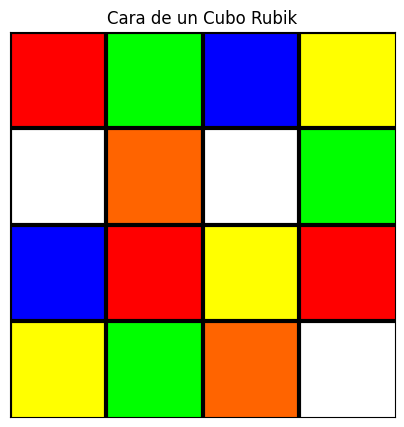

Dimensiones: (4, 4, 4)
Número de canales: 3 (RGB)


In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Crear una cara de cubo Rubik de 4x4
# Cada posición tiene un color RGB

cara = np.array([
[[255, 0, 0, 255], [0, 255, 0, 255], [0, 0, 255, 255], [255, 255, 0, 255]],

[[255, 255, 255, 255], [255, 100, 0, 255], [255, 255, 255, 255], [0, 255, 0, 255]],

[[0, 0, 255, 255], [255, 0, 0, 255], [255, 255, 0, 255], [255, 0, 0, 255]],

[[255, 255, 0, 255], [0, 255, 0, 255], [255, 100, 0, 255], [255, 255, 255, 255]]
], dtype=np.uint8)

# Mostrar la cara del cubo
plt.figure(figsize=(5, 5))
plt.imshow(cara, interpolation='nearest')

# Crear líneas para separar los cuadros
plt.xticks(np.arange(-0.5, 3, 1))
plt.yticks(np.arange(-0.5, 3, 1))
plt.grid(color='black', linewidth=3)

# Quitar los números de los ejes
plt.tick_params(
    axis='both',
    which='both',
    bottom=False,
    left=False,
    labelbottom=False,
    labelleft=False
)

plt.title("Cara de un Cubo Rubik")
plt.show()

# Mostrar las dimensiones
print("Dimensiones:", cara.shape)
print("Número de canales: 3 (RGB)")

# **Ejercicio 34**

Modifique los vectores del ejemplo de similitud coseno y encuentre:

dos vectores muy similares; dos vectores ortogonales; dos vectores en direcciones opuestas.

Similitud coseno a-b: 0.9999999999999998
Similitud coseno a-c: 0.0


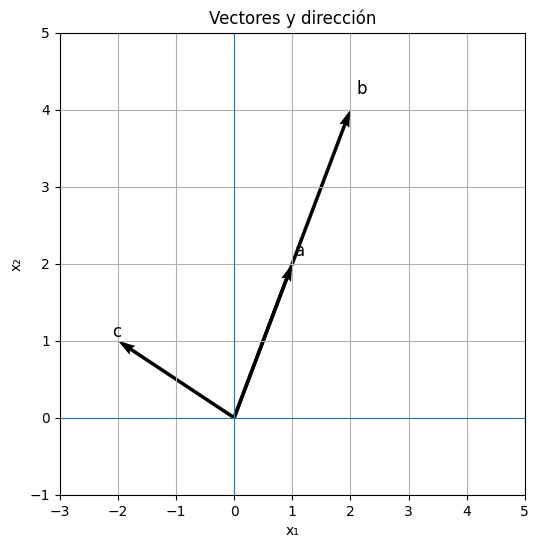

In [2]:
import numpy as np
import matplotlib.pyplot as plt
a = np.array([1., 2.])
b = np.array([2., 4.])
c = np.array([-2., 1.])

def cosine_similarity_manual(x, y):
    return np.dot(x, y) / (np.linalg.norm(x) * np.linalg.norm(y))

print("Similitud coseno a-b:", cosine_similarity_manual(a, b))
print("Similitud coseno a-c:", cosine_similarity_manual(a, c))

plt.figure(figsize=(6,6))
origen = np.zeros(2)
for v, nombre in [(a,"a"), (b,"b"), (c,"c")]:
    plt.quiver(*origen, *v, angles='xy', scale_units='xy', scale=1)
    plt.text(v[0]*1.05, v[1]*1.05, nombre, fontsize=12)

plt.xlim(-3,5)
plt.ylim(-1,5)
plt.axhline(0, linewidth=0.8)
plt.axvline(0, linewidth=0.8)
plt.grid(True)
plt.title("Vectores y dirección")
plt.xlabel("x₁")
plt.ylabel("x₂")
plt.show()

Similitud coseno a-b: 0.999952873536108
Similitud coseno a-c: 0.0
Similitud coseno a-d: -0.9999999999999998


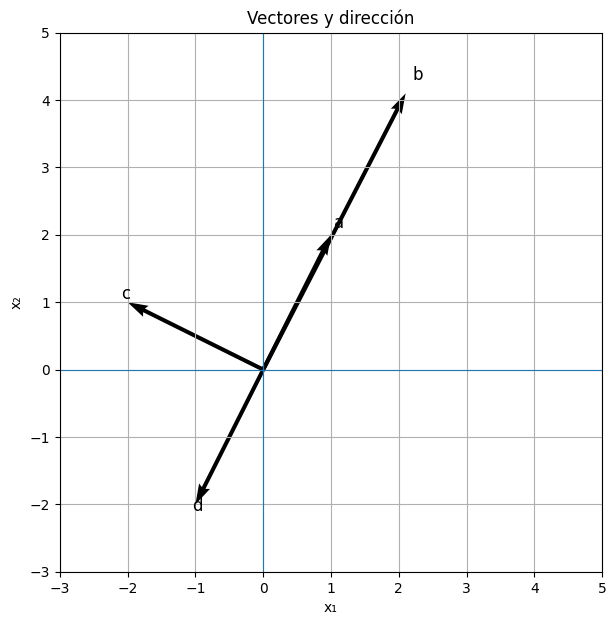

In [3]:
import matplotlib.pyplot as plt
a = np.array([1., 2.])
b = np.array([2.1, 4.1])
c = np.array([-2., 1.])
d = np.array([-1., -2.])


#Función para calcular la similitud
def cosine_similarity_manual(x, y):
    return np.dot(x, y) / (np.linalg.norm(x) * np.linalg.norm(y))

#Resultados
print("Similitud coseno a-b:", cosine_similarity_manual(a, b))
print("Similitud coseno a-c:", cosine_similarity_manual(a, c))
print("Similitud coseno a-d:", cosine_similarity_manual(a, d))

#Gráfica

plt.figure(figsize=(7,7))
origen = np.zeros(2)
for v, nombre in [(a,"a"), (b,"b"), (c,"c"), (d,"d")]:
    plt.quiver(*origen, *v, angles='xy', scale_units='xy', scale=1)
    plt.text(v[0]*1.05, v[1]*1.05, nombre, fontsize=12)

plt.xlim(-3,5)
plt.ylim(-3,5)
plt.axhline(0, linewidth=0.8)
plt.axvline(0, linewidth=0.8)
plt.grid(True)
plt.title("Vectores y dirección")
plt.xlabel("x₁")
plt.ylabel("x₂")
plt.show()

# SESIÓN 2 — Cómo aprende matemáticamente una IA

## Resultados de aprendizaje

Al finalizar esta sesión el estudiante podrá:

1. Comprender el concepto de parámetro entrenable.
2. Interpretar una función de pérdida.
3. Entender el gradiente.
4. Implementar descenso de gradiente desde cero.
5. Relacionar una neurona artificial con álgebra lineal, cálculo y probabilidad.

## 1. De una función a un modelo entrenable

Supongamos:

$$
\hat y=wx+b
$$

Aquí:

- \$(x\$): dato de entrada.
- \$(w\$): peso.
- \$(b\$): sesgo.
- \$(\hat y$\): predicción.

El problema de aprendizaje consiste en encontrar \$(w\$) y \$(b\$) que produzcan predicciones cercanas a los valores reales.

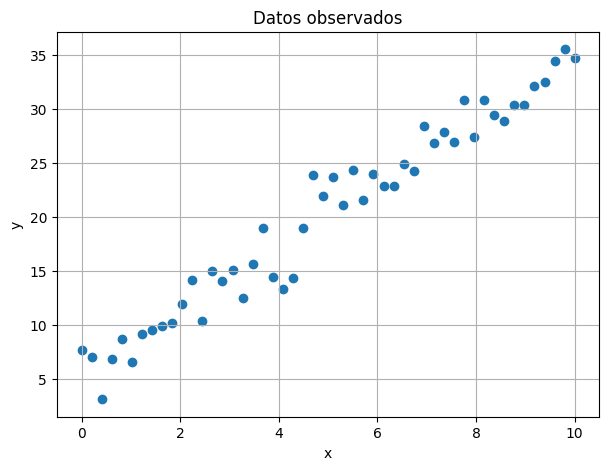

In [6]:
# Datos sintéticos
np.random.seed(10)

x = np.linspace(0,10,50)
ruido = np.random.normal(0,2,size=len(x))
y = 3*x + 5 + ruido

plt.figure(figsize=(7,5))
plt.scatter(x,y)
plt.title("Datos observados")
plt.xlabel("x")
plt.ylabel("y")
plt.grid(True)
plt.show()

# Al observar la gráfica, se puede ver que cuando X aumenta Y también lo hace, y aunque hay algunas pequeñas variaciones entre los datos, la tendencia general nos indica que va en aumento.

## 2. Función de pérdida

Para saber si un modelo es bueno necesitamos medir su error.

Una función común para regresión es el **error cuadrático medio**:

$$
MSE=
\frac{1}{n}
\sum_{i=1}^{n}
(y_i-\hat y_i)^2
$$

Si:

$$
\hat y_i=wx_i+b
$$

entonces:

$$
J(w,b)=
\frac{1}{n}
\sum_{i=1}^{n}
(y_i-(wx_i+b))^2
$$

El entrenamiento consiste en buscar parámetros que minimicen \$(J\$).

In [7]:
def mse(y_real, y_pred):
    return np.mean((y_real-y_pred)**2)

modelos = [
    (1,0),
    (2,2),
    (3,5),
    (4,7)
]

for w,b in modelos:
    pred = w*x+b
    print(f"w={w}, b={b}, MSE={mse(y,pred):.3f}")

w=1, b=0, MSE=267.714
w=2, b=2, MSE=78.533
w=3, b=5, MSE=3.289
w=4, b=7, MSE=58.802


# Con esta prueba fue posible comparar varias rectas y ver cuál se ajustaba mejor a los datos, pude ver que los resultados muestran que hay una gran diferencia entre los errores obtenidos, ya que algunos son muy altos y otros bastante bajos y por eso el valor del error sirve como una guía para saber qué tan cerca está el modelo de los datos reales. Entre menor sea ese valor, mejor será el resultado obtenido.

## 3. Superficie del error

Podemos imaginar que cada combinación de parámetros genera un error distinto.

Para simplificar, fijaremos $b=5$ y cambiaremos $w$.

El objetivo es encontrar el punto donde la función de costo es mínima.

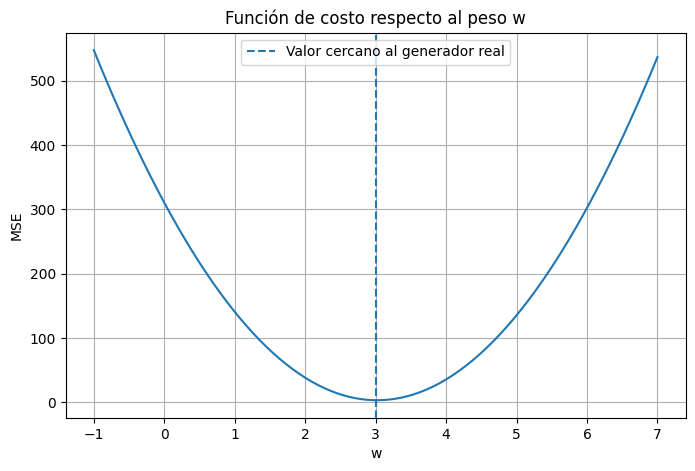

In [ ]:
ws = np.linspace(-1,7,250)
costos = []

b_fijo = 5

for w in ws:
    pred = w*x + b_fijo
    costos.append(mse(y,pred))

plt.figure(figsize=(8,5))
plt.plot(ws,costos)
plt.axvline(3, linestyle="--", label="Valor cercano al generador real")
plt.title("Función de costo respecto al peso w")
plt.xlabel("w")
plt.ylabel("MSE")
plt.grid(True)
plt.legend()
plt.show()

# La gráfica muestra que al cambiar el valor de w el error también cambia y hay un momento en el que el error llega a su nivel más bajo y luego vuelve a aumentar si seguimos moviendo el valor, esto ayuda a encontrar cuál es el valor que mejor le funciona al modelo, porque justo en esa parte es donde los resultados son más precisos y se parecen más a los datos originales.

## 4. Gradiente

El gradiente generaliza la idea de derivada.

Si:

$$
J=J(w,b)
$$

entonces:

$$
\nabla J=
\begin{bmatrix}
\frac{\partial J}{\partial w}\\
\frac{\partial J}{\partial b}
\end{bmatrix}
$$

Para el error cuadrático medio:

$$
\frac{\partial J}{\partial w}
=
-\frac{2}{n}
\sum_{i=1}^{n}x_i(y_i-\hat y_i)
$$

$$
\frac{\partial J}{\partial b}
=
-\frac{2}{n}
\sum_{i=1}^{n}(y_i-\hat y_i)
$$

El gradiente señala la dirección de mayor incremento del error.

Para disminuirlo nos movemos en sentido contrario.

## 5. Descenso de gradiente

Actualizamos los parámetros mediante:

$$
w_{nuevo}=w-\alpha\frac{\partial J}{\partial w}
$$



$$
b_{nuevo}=b-\alpha\frac{\partial J}{\partial b}
$$

donde $\alpha\$ es la **tasa de aprendizaje** (*learning rate*).

Esta es una de las ideas matemáticas centrales del entrenamiento de redes neuronales.

In [ ]:
# Descenso de gradiente implementado desde cero

w = 0.0
b = 0.0
alpha = 0.01
epocas = 2000

historial = []

n = len(x)

for epoca in range(epocas):
    y_pred = w*x + b

    error = y - y_pred

    dw = -(2/n)*np.sum(x*error)
    db = -(2/n)*np.sum(error)

    w = w - alpha*dw
    b = b - alpha*db

    costo = mse(y,y_pred)
    historial.append(costo)

print("Peso aprendido w =", round(w,4))
print("Sesgo aprendido b =", round(b,4))
print("MSE final =", round(historial[-1],4))

Peso aprendido w = 2.9592
Sesgo aprendido b = 5.4091
MSE final = 3.2324


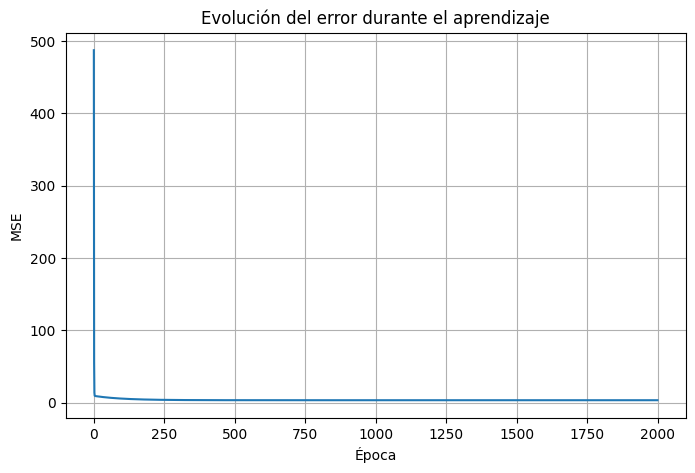

In [ ]:
plt.figure(figsize=(8,5))
plt.plot(historial)
plt.title("Evolución del error durante el aprendizaje")
plt.xlabel("Época")
plt.ylabel("MSE")
plt.grid(True)
plt.show()

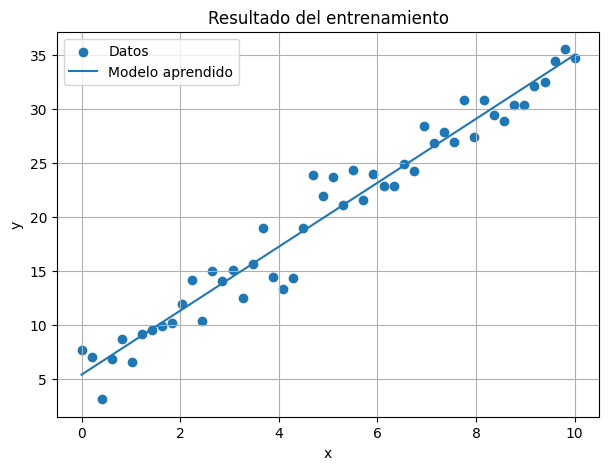

In [ ]:
plt.figure(figsize=(7,5))
plt.scatter(x,y,label="Datos")
plt.plot(x,w*x+b,label="Modelo aprendido")
plt.xlabel("x")
plt.ylabel("y")
plt.title("Resultado del entrenamiento")
plt.grid(True)
plt.legend()
plt.show()

# En esta prueba el modelo fue ajustando poco a poco los valores de w y b hasta encontrar una combinación que redujera el error lo más posible, al final se obtuvo un valor de w = 2.9592 y b = 5.4091, que son muy cercanos a los valores con los que se generaron los datos y el error final fue de 3.2324, lo que indica que el modelo logró aprender correctamente el comportamiento de los datos, tambien puedo observar que en la gráfica el error disminuye rápidamente al principio y luego se estabiliza esta es una señal de que el modelo encontró una buena solución.

## 6. La tasa de aprendizaje

El parámetro $\alpha$ controla el tamaño de cada paso.

- Muy pequeña: aprendizaje lento.
- Adecuada: convergencia estable.
- Muy grande: puede oscilar o divergir.

Experimentemos.

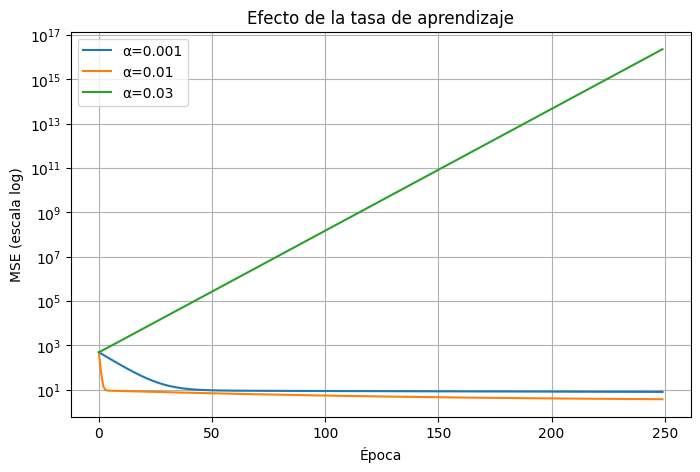

In [ ]:
def entrenar_lr(alpha, epocas=250):
    w_local = 0.0
    b_local = 0.0
    hist = []
    n = len(x)

    for _ in range(epocas):
        pred = w_local*x+b_local
        error = y-pred
        dw = -(2/n)*np.sum(x*error)
        db = -(2/n)*np.sum(error)
        w_local -= alpha*dw
        b_local -= alpha*db

        costo = mse(y, pred)
        if np.isfinite(costo):
            hist.append(costo)
        else:
            break
    return hist

tasas = [0.001, 0.01, 0.03]

plt.figure(figsize=(8,5))
for lr in tasas:
    h = entrenar_lr(lr)
    plt.plot(h,label=f"α={lr}")

plt.yscale("log")
plt.xlabel("Época")
plt.ylabel("MSE (escala log)")
plt.title("Efecto de la tasa de aprendizaje")
plt.grid(True)
plt.legend()
plt.show()

# Al probar distintos valores la tasa de aprendizaje para ver cómo cambiaba el error durante el entrenamiento, pude observar que con α = 0.01 el error disminuye de forma rápida y estable, logrando buenos resultados y que con α = 0.001 el aprendizaje también funciona, pero tarda más tiempo en reducir el error. Por otro lado puedo notar que con α = 0.03 el error aumenta demasiado y el modelo no logra encontrar una buena solución, esto demuestra que elegir una tasa de aprendizaje adecuada es importante para que el modelo pueda aprender correctamente.

## 7. De la regresión a una neurona artificial

Una neurona calcula primero:

$$
z=\mathbf{x}\cdot\mathbf{w}+b
$$

y después aplica una función de activación:

$$
a=g(z)
$$

Para clasificación binaria es común usar la función sigmoide:

$$
\sigma(z)=\frac{1}{1+e^{-z}}
$$

Su salida está entre 0 y 1 y puede interpretarse como una probabilidad.

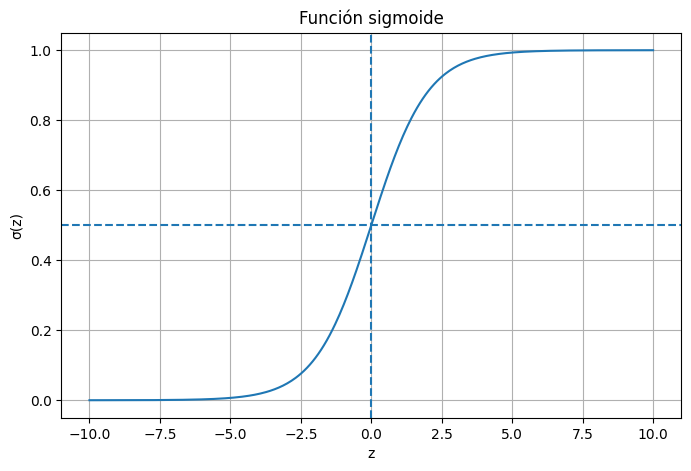

In [ ]:
def sigmoid(z):
    return 1/(1+np.exp(-z))

z = np.linspace(-10,10,400)
p = sigmoid(z)

plt.figure(figsize=(8,5))
plt.plot(z,p)
plt.axhline(0.5,linestyle="--")
plt.axvline(0,linestyle="--")
plt.xlabel("z")
plt.ylabel("σ(z)")
plt.title("Función sigmoide")
plt.grid(True)
plt.show()

# En este ejercicio se muestra cómo funciona una neurona artificial, primero toma los datos de entrada y realiza un cálculo, y después aplica una función llamada sigmoide, la gráfica me permite ver cómo los valores se transforman para quedar siempre entre 0 y 1. Cuando los valores de entrada son muy bajos el resultado se acerca a 0, y cuando son muy altos el resultado se acerca a 1, por eso esta función es útil cuando se necesita decidir entre dos posibles resultados o calcular una probabilidad.

### Ejemplo de una neurona

Suponga:

$$
\mathbf{x}=[0.8,0.4]
$$

$$
\mathbf{w}=[2,-1]
$$

$$
b=-0.2
$$

Primero:

$$
z=\mathbf{x}\cdot\mathbf{w}+b
$$

Después:

$$
P(Y=1|X)=\sigma(z)
$$

In [ ]:
x_neurona = np.array([0.8,0.4])
w_neurona = np.array([2.0,-1.0])
b_neurona = -0.2

z = np.dot(x_neurona,w_neurona)+b_neurona
prob = sigmoid(z)

print("z =", z)
print("Probabilidad =", prob)
print("Clase predicha =", int(prob>=0.5))

z = 1.0000000000000002
Probabilidad = 0.7310585786300049
Clase predicha = 1


## 8. Entropía cruzada

Para clasificación binaria se utiliza frecuentemente:

$$
L=
-\left[
y\log(p)
+
(1-y)\log(1-p)
\right]
$$

Si la clase real es $y=1$:

- una predicción $p=0.99$ produce una pérdida pequeña;
- una predicción $p=0.01$ produce una pérdida muy grande.

Esto penaliza con fuerza las predicciones incorrectas realizadas con alta confianza.

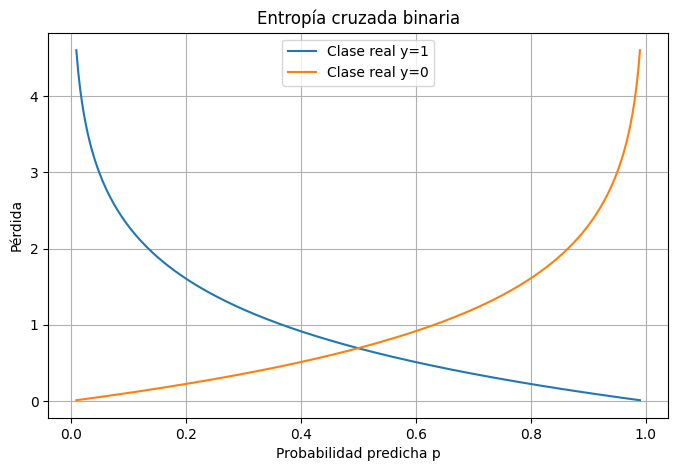

In [ ]:
def binary_cross_entropy(y_true, p):
    eps = 1e-12
    p = np.clip(p,eps,1-eps)
    return -(y_true*np.log(p)+(1-y_true)*np.log(1-p))

probabilidades = np.linspace(0.01,0.99,300)

loss_y1 = [binary_cross_entropy(1,p) for p in probabilidades]
loss_y0 = [binary_cross_entropy(0,p) for p in probabilidades]

plt.figure(figsize=(8,5))
plt.plot(probabilidades,loss_y1,label="Clase real y=1")
plt.plot(probabilidades,loss_y0,label="Clase real y=0")
plt.xlabel("Probabilidad predicha p")
plt.ylabel("Pérdida")
plt.title("Entropía cruzada binaria")
plt.grid(True)
plt.legend()
plt.show()

# La gráfica muestra que cuando el modelo acierta el error es pequeño, pero cuando se equivoca el error aumenta rápidamente y entre más seguro esté de una respuesta incorrecta mayor será la penalización que recibe. Gracias a esto, el modelo puede aprender de sus errores y ajustar sus valores para hacer predicciones cada vez mejores.

## 9. Clasificación completa

Ahora generaremos un pequeño problema de clasificación con dos características.

El objetivo es visualizar cómo un modelo aprende una frontera que separa dos clases.

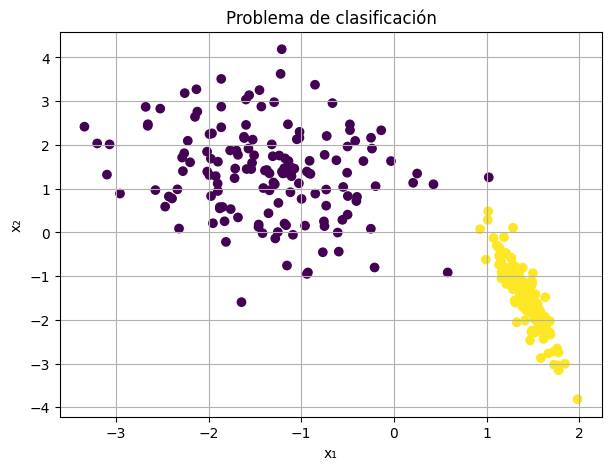

In [ ]:
Xc, yc = make_classification(
    n_samples=300,
    n_features=2,
    n_redundant=0,
    n_informative=2,
    n_clusters_per_class=1,
    class_sep=1.4,
    random_state=7
)

plt.figure(figsize=(7,5))
plt.scatter(Xc[:,0],Xc[:,1],c=yc)
plt.xlabel("x₁")
plt.ylabel("x₂")
plt.title("Problema de clasificación")
plt.grid(True)
plt.show()

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    Xc, yc, test_size=0.3, random_state=42, stratify=yc
)

modelo = LogisticRegression()
modelo.fit(X_train,y_train)

pred = modelo.predict(X_test)
prob = modelo.predict_proba(X_test)[:,1]

print("Pesos:", modelo.coef_)
print("Sesgo:", modelo.intercept_)
print("Accuracy:", accuracy_score(y_test,pred))

Pesos: [[ 2.7662 -1.4339]]
Sesgo: [-1.0746]
Accuracy: 0.9888888888888889


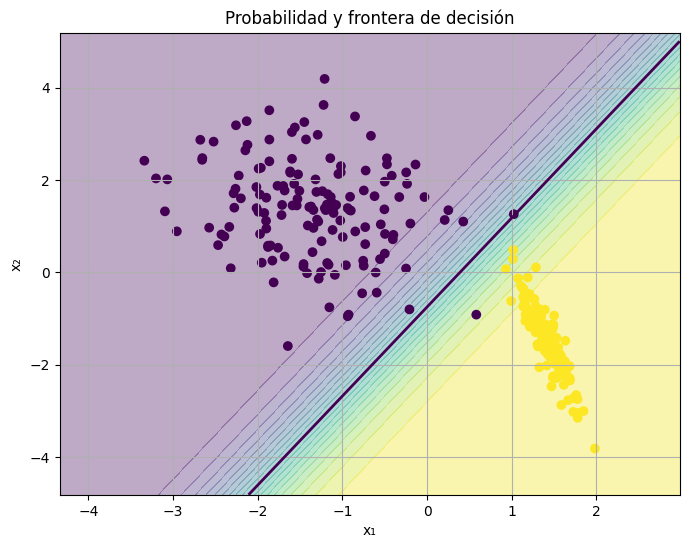

In [ ]:
# Frontera de decisión

x_min, x_max = Xc[:,0].min()-1, Xc[:,0].max()+1
y_min, y_max = Xc[:,1].min()-1, Xc[:,1].max()+1

xx, yy = np.meshgrid(
    np.linspace(x_min,x_max,300),
    np.linspace(y_min,y_max,300)
)

grid = np.c_[xx.ravel(), yy.ravel()]
zz = modelo.predict_proba(grid)[:,1].reshape(xx.shape)

plt.figure(figsize=(8,6))
plt.contourf(xx,yy,zz,levels=20,alpha=0.35)
plt.contour(xx,yy,zz,levels=[0.5],linewidths=2)
plt.scatter(Xc[:,0],Xc[:,1],c=yc)
plt.xlabel("x₁")
plt.ylabel("x₂")
plt.title("Probabilidad y frontera de decisión")
plt.grid(True)
plt.show()

# Con esta prueba puedo ver que el modelo aprendió a diferenciar los dos grupos de datos casi sin equivocarse, los puntos de cada grupo quedaron bien separados y la frontera de decisión ayuda a marcar el límite entre una clase y la otra, el resultado fue bastante bueno porque alcanzó una precisión cercana al 99%, lo que significa que acertó en casi todos los casos evaluados.

## 10. Una red neuronal vista como composición de funciones

Una red neuronal con una capa oculta puede escribirse como:

$$
\mathbf{h}=g(W_1\mathbf{x}+\mathbf{b}_1)
$$

$$
\hat{\mathbf{y}}=f(W_2\mathbf{h}+\mathbf{b}_2)
$$

Por tanto, una red neuronal no es magia: es una **composición de operaciones matemáticas**.

Intervienen:

- vectores,
- matrices,
- productos punto,
- funciones,
- derivadas,
- probabilidades,
- optimización.

In [ ]:
# Propagación hacia adelante de una pequeña red neuronal, sin TensorFlow/PyTorch

def relu(z):
    return np.maximum(0,z)

x_demo = np.array([[0.6],[-1.2]])

W1 = np.array([
    [0.7,-0.4],
    [1.1, 0.3],
    [-0.5,0.8]
])
b1 = np.array([[0.1],[0.0],[-0.2]])

W2 = np.array([[0.6,-1.0,0.9]])
b2 = np.array([[0.2]])

z1 = W1 @ x_demo + b1
h = relu(z1)
z2 = W2 @ h + b2
salida = sigmoid(z2)

print("Entrada x:")
print(x_demo)

print("\nActivaciones capa oculta:")
print(h)

print("\nSalida probabilística:")
print(salida)

Entrada x:
[[ 0.6]
 [-1.2]]

Activaciones capa oculta:
[[1. ]
 [0.3]
 [0. ]]

Salida probabilística:
[[0.6225]]


# En esta prueba se observa cómo una red neuronal procesa los datos paso a paso hasta obtener un resultado final, la salida fue 0.6225, lo que indica una probabilidad cercana al 62%, mostrando cómo la red utiliza la información de entrada para generar una predicción.

# Actividad integradora — Sesión 2

### Parte A — Interpretación
Explique qué representa cada componente:

$$
\hat y=wx+b
$$


- $x$
- $w$
- $b$
- $\hat y\$

### Parte B — Cálculo
Para:

$$
J(w)=(w-4)^2
$$

1. Calcule $\frac{dJ}{dw}$.
2. Determine el valor de $w$ que minimiza $J$.
3. Realice tres pasos de descenso de gradiente iniciando en $w=0$, usando $\alpha=0.1$.

### Parte C — Experimentación
Cambie la tasa de aprendizaje del ejemplo:

- $\alpha=0.0001$
- $\alpha=0.01$
- $\alpha=0.05$
- $\alpha=0.1$

Observe qué sucede con la función de costo.

### Parte D — Reflexión
Explique en máximo cinco líneas:

> ¿Por qué entrenar una IA puede entenderse matemáticamente como un problema de optimización?

# Síntesis final

Podemos resumir gran parte del aprendizaje automático como:

$$
\boxed{\text{Datos} \rightarrow \text{Modelo} \rightarrow \text{Predicción} \rightarrow \text{Error} \rightarrow \text{Gradiente} \rightarrow \text{Actualización}}
$$

Matemáticamente:

$$
\mathbf{x}
\overset{f_\theta}{\longrightarrow}
\hat y
$$

$$
L(y,\hat y)
$$

$$
\nabla_\theta L
$$

$$
\theta_{nuevo}
=
\theta_{actual}
-
\alpha\nabla_\theta L
$$

donde $\theta$ representa todos los parámetros que el modelo debe aprender.

## Conexión de conceptos

| Matemática | Uso en IA |
|---|---|
| Vectores | Representar características |
| Matrices | Representar conjuntos de datos y pesos |
| Producto punto | Neuronas y modelos lineales |
| Funciones | Transformar datos |
| Derivadas | Medir sensibilidad al cambio |
| Gradientes | Ajustar parámetros |
| Probabilidad | Expresar incertidumbre |
| Optimización | Entrenar modelos |
| Composición de funciones | Construir redes neuronales |

# Preguntas de evaluación rápida

1. **¿Qué representa una fila de una matriz de datos?**
**RTA:** Una fila representa un dato completo que el modelo va a analizar, por ejemplo en el problema de clasificación cada punto tenía valores de x1 y x2 y juntos formaban una fila dentro del conjunto de datos.
2. **¿Qué operación matemática realiza primero una neurona artificial?**
**RTA:** Lo primero que hace es combinar los datos de entrada para obtener un valor inicial, fue similar a lo que vi con la fórmula de la recta donde se utilizaron valores como w = 2.9592 y b = 5.4091 para generar una predicción.
3. **¿Qué indica una derivada?**
**RTA:** La derivada ayuda a saber hacia dónde debe moverse el modelo para reducir el error, gracias a eso el error pudo bajar desde valores cercanos a 500 hasta llegar aproximadamente a 3.23 durante el entrenamiento.
4. **¿Qué mide una función de costo?**
**RTA:** Mide qué tan lejos están los resultados del modelo frente a los datos reales, por ejemplo una recta tuvo un error de 267, mientras que otra logró un error de apenas 3.29, mostrando una gran diferencia en desempeño.
5. **¿Por qué el descenso de gradiente utiliza el signo negativo?**
**RTA:** Porque busca ir en la dirección en donde el error disminuye, poreso permitió que el modelo fuera mejorando poco a poco hasta encontrar valores cercanos a los correctos y asi pudo obtener un error mucho más bajo.
6. **¿Qué ocurre si la tasa de aprendizaje es demasiado alta?**
**RTA:** Pude notar que el modelo intenta avanzar demasiado rápido y termina equivocándose más y en la gráfica vi que con α = 0.03 el error crecía muchísimo en lugar de reducirse, mientras que con α = 0.01 el aprendizaje fue estable.
7. **¿Por qué la sigmoide puede utilizarse en clasificación binaria?**
**RTA:** Porque siempre entrega resultados entre 0 y 1 poreso en el ejemplo de la red neuronal se obtuvo una salida de 0.6225, que puedo interpretar como una probabilidad del 62% aproximadamente.
8. **¿Qué relación existe entre álgebra lineal y redes neuronales?**
**RTA:** Las redes neuronales trabajan constantemente con grupos de datos y valores que se organizan en matrices y cuando la red recibe una entrada, realiza operaciones con esos datos para obtener una salida por lo que el álgebra lineal está presente en casi todo el proceso que sigue la red para llegar a una predicción.
9. **¿Qué relación existe entre cálculo y entrenamiento?**
**RTA:** El cálculo ayuda a que el modelo se corrija durante el aprendizaje y gracias a eso es que los valores de w y b fueron ajustándose hasta llegar a w = 2.9592 y b = 5.4091, reduciendo el error al mínimo posible.
10. **¿Qué relación existe entre probabilidad y clasificación?**
**RTA:** La probabilidad permite decidir a qué grupo pertenece un dato y en el ejercicio de clasificación el modelo alcanzó una precisión cercana al 98.89%, utilizando probabilidades para separar correctamente las dos clases.

# Desafío opcional

Implemente sin usar `scikit-learn` un clasificador binario que utilice:

1. producto punto,
2. función sigmoide,
3. entropía cruzada,
4. descenso de gradiente.

Compare posteriormente los resultados con `LogisticRegression` de `scikit-learn`.

Este ejercicio reúne los principales conceptos matemáticos estudiados en las dos sesiones.

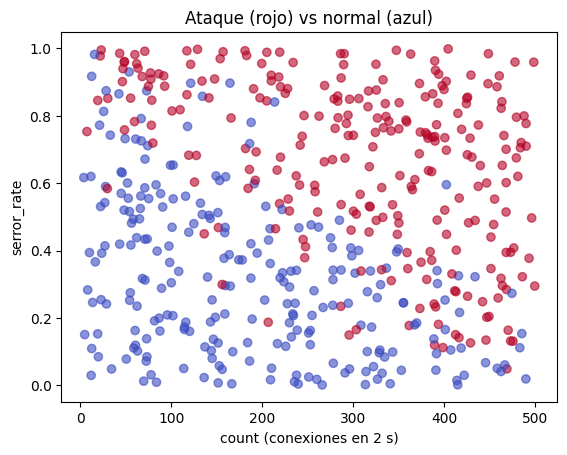

Exactitud: 0.81
Matriz de confusión:
 [[30 12]
 [ 7 51]]
              precision    recall  f1-score   support

           0       0.81      0.71      0.76        42
           1       0.81      0.88      0.84        58

    accuracy                           0.81       100
   macro avg       0.81      0.80      0.80       100
weighted avg       0.81      0.81      0.81       100

Predicción: [1]
Probabilidad [normal, ataque]: [[0.0281 0.9719]]


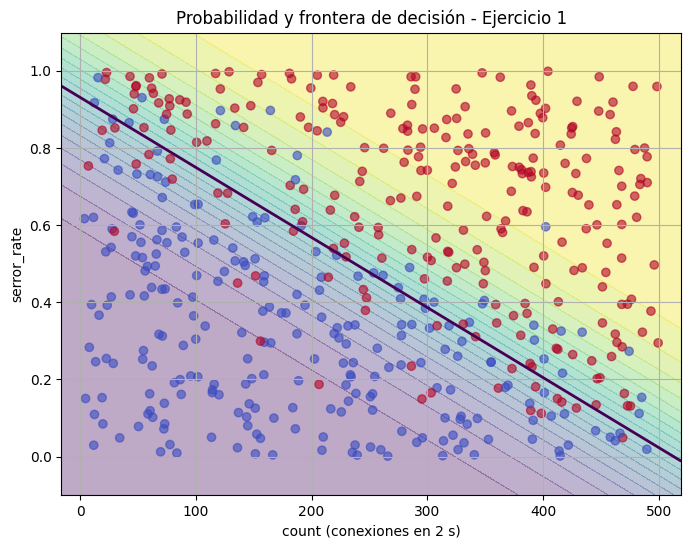

In [9]:
# Integrantes: Elkin Rodiño - Leidy Vargas - Jerson Moncada - Julian Ariza


# Plantee dos ejercicios de clasificación en machine learning sobre detección de intrusiones
# en redes, cada uno con dos variables predictoras y una variable objetivo binaria, usando datos sintéticos.

# ==============================================================================================================================================================
# Ejercicio 1: Detección de ataques DoS (denegación de servicio)
# Una empresa quiere detectar ataques de denegación de servicio en su red. Para esto se generaron 500 registros sintéticos de tráfico con dos variables predictoras:
# count: número de conexiones al mismo host en 2 segundos.
# serror_rate: tasa de errores SYN (proporción de conexiones fallidas).

# La variable objetivo es ataque, que vale 1 si el tráfico es un ataque DoS y 0 si es normal.
# La idea es que muchas conexiones junto con muchos errores indican un ataque.
# Se debe entrenar un modelo de regresión logística, evaluarlo con exactitud,
# matriz de confusión y reporte de clasificación, graficar su frontera de decisión y predecir un caso nuevo (300 conexiones y 80 % de errores SYN).

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# 1. Crear los datos sintéticos
rng = np.random.default_rng(42)
n = 500

count = rng.uniform(1, 500, n)        # conexiones al mismo host en 2 segundos
serror_rate = rng.uniform(0, 1, n)    # tasa de errores SYN

# Regla oculta: muchas conexiones + muchos errores = ataque
z = 0.01 * count + 6 * serror_rate - 5.5 + rng.normal(0, 1, n)
ataque = (z > 0).astype(int)          # 1 = ataque DoS, 0 = normal

df1 = pd.DataFrame({'count': count, 'serror_rate': serror_rate, 'ataque': ataque})

# 2. Gráfico
plt.scatter(df1['count'], df1['serror_rate'], c=df1['ataque'], cmap='coolwarm', alpha=0.6)
plt.xlabel('count (conexiones en 2 s)')
plt.ylabel('serror_rate')
plt.title('Ataque (rojo) vs normal (azul)')
plt.show()

# 3. Separar en entrenamiento y prueba
X = df1[['count', 'serror_rate']]
y = df1['ataque']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 4. Entrenar (con escalado, porque count y serror_rate tienen escalas muy distintas)
modelo = make_pipeline(StandardScaler(), LogisticRegression())
modelo.fit(X_train, y_train)
pred = modelo.predict(X_test)

# 5. Resultados
print('Exactitud:', accuracy_score(y_test, pred))
print('Matriz de confusión:\n', confusion_matrix(y_test, pred))
print(classification_report(y_test, pred))

# 6. Caso nuevo: 300 conexiones y 80% de errores SYN
nuevo = pd.DataFrame({'count': [300], 'serror_rate': [0.8]})
print('Predicción:', modelo.predict(nuevo))
print('Probabilidad [normal, ataque]:', modelo.predict_proba(nuevo))

# 7. Frontera de decisión - Ejercicio 1
x_min, x_max = df1['count'].min()-20, df1['count'].max()+20
y_min, y_max = df1['serror_rate'].min()-0.1, df1['serror_rate'].max()+0.1

xx, yy = np.meshgrid(
    np.linspace(x_min,x_max,300),
    np.linspace(y_min,y_max,300)
)

grid = pd.DataFrame(np.c_[xx.ravel(), yy.ravel()], columns=['count','serror_rate'])
zz = modelo.predict_proba(grid)[:,1].reshape(xx.shape)

plt.figure(figsize=(8,6))
plt.contourf(xx,yy,zz,levels=20,alpha=0.35)
plt.contour(xx,yy,zz,levels=[0.5],linewidths=2)
plt.scatter(df1['count'], df1['serror_rate'], c=df1['ataque'], cmap='coolwarm', alpha=0.6)
plt.xlabel("count (conexiones en 2 s)")
plt.ylabel("serror_rate")
plt.title("Probabilidad y frontera de decisión - Ejercicio 1")
plt.grid(True)
plt.show()


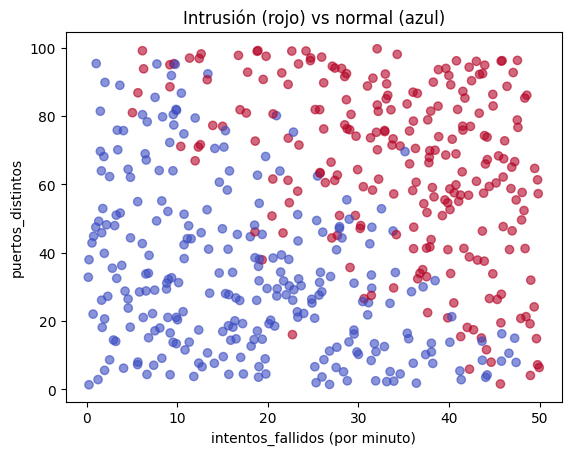

Exactitud: 0.85
Matriz de confusión:
 [[48  7]
 [ 8 37]]
              precision    recall  f1-score   support

           0       0.86      0.87      0.86        55
           1       0.84      0.82      0.83        45

    accuracy                           0.85       100
   macro avg       0.85      0.85      0.85       100
weighted avg       0.85      0.85      0.85       100

Predicción: [0]
Probabilidad [normal, intrusión]: [[0.542 0.458]]


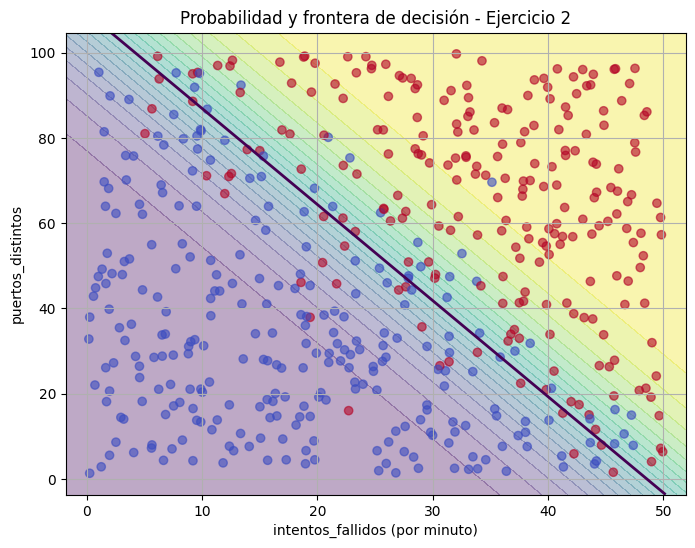

In [10]:
# Ejercicio 2: Detección de intrusiones por fuerza bruta y escaneo de puertos

# Se quiere identificar intentos de intrusión en un servidor. Se generaron 500 registros sintéticos con dos variables predictoras:

# intentos_fallidos: intentos de inicio de sesión fallidos por minuto.
# puertos_distintos: cantidad de puertos distintos contactados por una misma IP.

# La variable objetivo es intrusion, que vale 1 si la actividad es una intrusión (fuerza bruta o escaneo de puertos) y 0 si es normal.
# Se asume que muchos intentos fallidos junto con muchos puertos contactados indican un comportamiento sospechoso.

# Se debe entrenar un modelo de regresión logística, evaluar su desempeño, graficar la frontera de decisión y predecir
# un caso nuevo (30 intentos fallidos por minuto y 40 puertos distintos).

# 1. Crear los datos sintéticos



rng = np.random.default_rng(7)
n = 500

intentos_fallidos = rng.uniform(0, 50, n)    # intentos de login fallidos por minuto
puertos_distintos = rng.uniform(1, 100, n)   # puertos distintos contactados por una IP

# Regla oculta: muchos intentos fallidos + muchos puertos = intrusión
z = 0.12 * intentos_fallidos + 0.06 * puertos_distintos - 6 + rng.normal(0, 1, n)
intrusion = (z > 0).astype(int)              # 1 = intrusión, 0 = normal

df2 = pd.DataFrame({'intentos_fallidos': intentos_fallidos,
                    'puertos_distintos': puertos_distintos,
                    'intrusion': intrusion})

# 2. Gráfico
plt.scatter(df2['intentos_fallidos'], df2['puertos_distintos'], c=df2['intrusion'], cmap='coolwarm', alpha=0.6)
plt.xlabel('intentos_fallidos (por minuto)')
plt.ylabel('puertos_distintos')
plt.title('Intrusión (rojo) vs normal (azul)')
plt.show()

# 3. Separar en entrenamiento y prueba
X = df2[['intentos_fallidos', 'puertos_distintos']]
y = df2['intrusion']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 4. Entrenar (con escalado, porque las variables tienen escalas distintas)
modelo2 = make_pipeline(StandardScaler(), LogisticRegression())
modelo2.fit(X_train, y_train)
pred = modelo2.predict(X_test)

# 5. Resultados
print('Exactitud:', accuracy_score(y_test, pred))
print('Matriz de confusión:\n', confusion_matrix(y_test, pred))
print(classification_report(y_test, pred))

# 6. Caso nuevo: 30 intentos fallidos por minuto y 40 puertos distintos
nuevo = pd.DataFrame({'intentos_fallidos': [30], 'puertos_distintos': [40]})
print('Predicción:', modelo2.predict(nuevo))
print('Probabilidad [normal, intrusión]:', modelo2.predict_proba(nuevo))

# 7. Frontera de decisión - Ejercicio 2
x_min, x_max = df2['intentos_fallidos'].min()-2, df2['intentos_fallidos'].max()+2
y_min, y_max = df2['puertos_distintos'].min()-5, df2['puertos_distintos'].max()+5

xx, yy = np.meshgrid(
    np.linspace(x_min,x_max,300),
    np.linspace(y_min,y_max,300)
)

grid = pd.DataFrame(np.c_[xx.ravel(), yy.ravel()], columns=['intentos_fallidos','puertos_distintos'])
zz = modelo2.predict_proba(grid)[:,1].reshape(xx.shape)

plt.figure(figsize=(8,6))
plt.contourf(xx,yy,zz,levels=20,alpha=0.35)
plt.contour(xx,yy,zz,levels=[0.5],linewidths=2)
plt.scatter(df2['intentos_fallidos'], df2['puertos_distintos'], c=df2['intrusion'], cmap='coolwarm', alpha=0.6)
plt.xlabel("intentos_fallidos (por minuto)")
plt.ylabel("puertos_distintos")
plt.title("Probabilidad y frontera de decisión - Ejercicio 2")
plt.grid(True)
plt.show()